# AI Model Experiment & Evaluation — Sentiment Analysis Ulasan Pelanggan

**Individual Assignment — AI Engineering Bootcamp**

Notebook ini membandingkan dua pendekatan untuk klasifikasi sentimen ulasan pelanggan e-commerce:

1. **Pendekatan 1 — Model klasik**: TF-IDF + classifier Scikit-learn yang dilatih sendiri.
2. **Pendekatan 2 — LLM API**: Gemini API dengan prompting (zero-shot & few-shot), tanpa training.

Kedua pendekatan dievaluasi pada **test set yang identik** agar perbandingan adil.

Struktur section mengikuti starter notebook. Beberapa sub-section tambahan (6.4, 6.5) ditambahkan
untuk analisis lanjutan, tanpa mengubah urutan section utama.

## 1. Problem Statement

### 1.1 Objective

Tim produk e-commerce ingin membangun fitur otomatis yang mengklasifikasikan sentimen ulasan
pelanggan pada halaman produk. Tujuan eksperimen ini **bukan** membangun sistem produksi, melainkan
menjawab satu pertanyaan keputusan:

> Pendekatan mana — melatih model klasik sendiri, atau memanggil LLM API dengan prompt — yang
> sebaiknya dikembangkan lebih lanjut untuk use case ini?

Jawabannya harus didukung bukti kuantitatif (metrik evaluasi pada test set yang sama) dan
analisis trade-off (effort implementasi, kecepatan, biaya).

### 1.2 Target / Label yang Diprediksi

Task ini adalah **binary text classification**. Untuk setiap ulasan (`review_text`), model
memprediksi satu dari dua label pada kolom `sentiment`:

| Label | Arti | Contoh |
|---|---|---|
| `positif` | Pelanggan puas terhadap produk, pengiriman, atau pelayanan | *"Barangnya bagus banget, sesuai foto dan pengiriman cepat!"* |
| `negatif` | Pelanggan kecewa terhadap produk, pengiriman, atau pelayanan | *"Kualitas produk jelek, baru dipakai sekali sudah rusak."* |

Tidak ada kelas `netral` dalam dataset, sehingga ruang keputusan model dibatasi pada dua label di atas.

**Kelas yang paling penting secara bisnis adalah `negatif`.** Ulasan negatif adalah sinyal yang
dapat ditindaklanjuti (eskalasi ke CS, audit seller, penarikan listing), sementara ulasan positif
umumnya tidak menuntut aksi. Karena itu selain metrik macro-average, laporan ini juga menyoroti
**recall kelas `negatif`** — seberapa banyak keluhan nyata yang berhasil tertangkap.

### 1.3 Batasan dan Asumsi

**Batasan (constraints):**

- **Dataset tetap.** Hanya `data/customer_reviews_sentiment.csv` yang digunakan; dataset asli tidak
  dimodifikasi. Semua transformasi dilakukan pada salinan di memori.
- **Split yang ditentukan.** Split mengikuti starter notebook: `test_size=0.2`, `random_state=42`,
  `stratify=y` — agar hasil dapat dinilai dengan parameter yang sama.
- **Test set identik.** Kedua pendekatan dievaluasi pada test set yang persis sama.
- **Tanpa training Deep Learning dari nol**, sesuai ketentuan brief.
- **Tanpa fine-tuning LLM.** Pendekatan 2 murni prompting.

**Asumsi (assumptions):**

- **Label dataset dianggap ground truth**, meskipun tidak ada informasi tentang proses anotasinya.
- **Setiap ulasan punya satu sentimen dominan** yang dapat diwakili satu label.
- **Distribusi dataset dianggap mewakili** ulasan produksi. Asumsi ini diperiksa — dan sebagian
  terbantahkan — pada Section 2.3; implikasinya dibahas di Section 7.
- **Biaya API diestimasi** dari token yang benar-benar terpakai pada eksperimen ini, bukan dari
  asumsi panjang teks.

## 2. Import Library & Load Dataset

In [1]:
from __future__ import annotations

import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=UserWarning)

# --- Paths: notebook berjalan dari notebook/, jadi root project adalah parent-nya ---
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebook" else CWD
DATA_PATH = ROOT / "data" / "customer_reviews_sentiment.csv"
RESULTS_DIR = ROOT / "results"
DOCS_DIR = ROOT / "documentation"
RESULTS_DIR.mkdir(exist_ok=True)
DOCS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TEXT_COL, LABEL_COL = "review_text", "sentiment"
LABELS = ["negatif", "positif"]          # urutan tetap untuk confusion matrix
BUSINESS_POS_LABEL = "negatif"           # kelas yang paling penting ditangkap

pd.set_option("display.max_colwidth", 80)
print(f"Project root : {ROOT}")
print(f"Dataset      : {DATA_PATH.relative_to(ROOT)}")

Project root : /Users/benedictamoudywiyono/Documents/Personal/monica/model-experiment-assignment
Dataset      : data/customer_reviews_sentiment.csv


In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Kolom: {list(df.columns)}")
df.head()

Shape: 200 baris x 4 kolom
Kolom: ['review_id', 'product_name', 'review_text', 'sentiment']


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat dikomplain.,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan barang aman.",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif


### 2.1 Pemeriksaan Kualitas Data

Sebelum split, dataset diperiksa untuk missing value, distribusi kelas, dan — yang akan terbukti
paling menentukan — **duplikasi teks ulasan**.

In [3]:
print("=== Missing value per kolom ===")
print(df.isna().sum().to_string())

print("\n=== Distribusi label ===")
dist = df[LABEL_COL].value_counts()
for label, n in dist.items():
    print(f"  {label:>8}: {n:>3} ({n / len(df):.1%})")
print(f"  imbalance ratio: {dist.max() / dist.min():.2f} : 1")

print("\n=== Statistik panjang ulasan ===")
lengths = df[TEXT_COL].str.split().str.len()
print(f"  kata  : min {lengths.min()}, median {lengths.median():.0f}, max {lengths.max()}")
print(f"  produk: {df['product_name'].nunique()} nama produk unik")

=== Missing value per kolom ===
review_id       0
product_name    0
review_text     0
sentiment       0

=== Distribusi label ===
   positif: 110 (55.0%)
   negatif:  90 (45.0%)
  imbalance ratio: 1.22 : 1

=== Statistik panjang ulasan ===
  kata  : min 6, median 8, max 11
  produk: 15 nama produk unik


In [4]:
n_total = len(df)
n_unique = df[TEXT_COL].nunique()

print("=== Pemeriksaan duplikasi teks ulasan ===")
print(f"  Total baris          : {n_total}")
print(f"  Teks ulasan unik     : {n_unique}")
print(f"  Baris duplikat       : {n_total - n_unique} ({(n_total - n_unique) / n_total:.1%})")

repeats = df[TEXT_COL].value_counts()
print(f"  Pengulangan per teks : min {repeats.min()}, median {repeats.median():.0f}, max {repeats.max()}")

conflicting = df.groupby(TEXT_COL)[LABEL_COL].nunique()
print(f"  Teks dengan label bertentangan: {(conflicting > 1).sum()}  (0 = label konsisten)")

unique_dist = df.drop_duplicates(TEXT_COL)[LABEL_COL].value_counts()
print(f"\n  Distribusi pada {n_unique} teks unik:")
for label, n in unique_dist.items():
    print(f"    {label:>8}: {n}")

=== Pemeriksaan duplikasi teks ulasan ===
  Total baris          : 200
  Teks ulasan unik     : 40
  Baris duplikat       : 160 (80.0%)
  Pengulangan per teks : min 1, median 5, max 12
  Teks dengan label bertentangan: 0  (0 = label konsisten)

  Distribusi pada 40 teks unik:
     negatif: 20
     positif: 20


### 2.2 Interpretasi Pemeriksaan Data

- **Tidak ada missing value** pada keempat kolom, sehingga tidak diperlukan imputasi atau pembuangan baris.
- **Distribusi label sedikit tidak seimbang** (110 `positif` vs 90 `negatif`, rasio 1.22 : 1). Ketimpangan
  sekecil ini tidak memerlukan penanganan khusus seperti resampling, tetapi berarti **accuracy saja tidak cukup**:
  model yang selalu menebak `positif` sudah memperoleh accuracy 55%. Karena itu laporan ini selalu
  menyertakan precision, recall, dan F1 macro-average.
- **Ulasan sangat pendek** (median 8 kata) dan hanya melibatkan 15 nama produk.
- **Temuan paling penting: dari 200 baris, hanya 40 teks ulasan yang benar-benar unik** — setiap teks diulang
  antara 1 sampai 12 kali. Pada tingkat teks unik, dataset justru seimbang sempurna (20 `positif`, 20 `negatif`),
  dan label selalu konsisten untuk teks yang sama.

Temuan terakhir punya konsekuensi serius yang dibahas berikut ini.

### 2.3 Konsekuensi Duplikasi: Kebocoran Data (Data Leakage)

Karena hanya ada 40 teks unik yang tersebar di 200 baris, **random split akan menempatkan salinan
persis dari hampir setiap ulasan test ke dalam training set**. Model klasik tidak perlu belajar
menggeneralisasi bahasa — cukup menghafal teks yang sudah pernah dilihatnya. Skor test yang
dihasilkan akan mendekati sempurna, tetapi angka itu **mengukur hafalan, bukan kemampuan
generalisasi**.

Pendekatan LLM tidak terpengaruh masalah ini: Gemini tidak pernah melihat training set sama sekali,
sehingga setiap prediksi selalu bersifat "data baru" baginya.

Melaporkan hanya angka dari split yang ditentukan akan **menguntungkan model klasik secara tidak
adil**. Karena itu notebook ini menjalankan dua eksperimen:

| | Eksperimen A (utama) | Eksperimen B (tambahan) |
|---|---|---|
| **Data** | 200 baris, split sesuai brief | 40 teks unik (deduplikasi) |
| **Split** | `test_size=0.2, random_state=42, stratify=y` | 5-fold CV, prediksi out-of-fold |
| **Kebocoran** | Ada — teks test muncul di training | Tidak ada — fold test tidak pernah dilatihkan |
| **Peran** | Deliverable sesuai brief | Estimasi generalisasi yang jujur |

Eksperimen A adalah hasil resmi yang diminta brief. Eksperimen B (Section 6.4) menguji apakah
kesimpulan Eksperimen A bertahan setelah kebocoran dihilangkan.

## 3. Menyiapkan Train/Test Split

Split mengikuti parameter starter notebook persis: `test_size=0.2`, `random_state=42`, `stratify=y`.
`random_state` yang tetap membuat split ini **deterministik dan reproducible** — inilah yang menjamin
kedua pendekatan dievaluasi pada test set yang identik, bahkan jika notebook dijalankan ulang di mesin lain.

In [5]:
X = df[TEXT_COL]
y = df[LABEL_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train size: {len(X_train)}")
print(f"Test size : {len(X_test)}")

print("\nDistribusi label (stratify menjaga proporsi tetap sama):")
comparison = pd.DataFrame({
    "train": y_train.value_counts(),
    "train %": (y_train.value_counts(normalize=True) * 100).round(1),
    "test": y_test.value_counts(),
    "test %": (y_test.value_counts(normalize=True) * 100).round(1),
})
print(comparison.to_string())

# Test set disimpan agar dapat diaudit / digunakan ulang tanpa menjalankan notebook.
test_set_df = pd.DataFrame({"review_text": X_test, "sentiment_true": y_test})
test_set_df.to_csv(RESULTS_DIR / "test_set.csv", index=False)
print(f"\nTest set disimpan ke results/test_set.csv ({len(test_set_df)} baris)")

Train size: 160
Test size : 40

Distribusi label (stratify menjaga proporsi tetap sama):
           train  train %  test  test %
sentiment                              
positif       88     55.0    22    55.0
negatif       72     45.0    18    45.0

Test set disimpan ke results/test_set.csv (40 baris)


In [6]:
# Verifikasi kuantitatif atas kebocoran yang dibahas di Section 2.3.
leaked = X_test.isin(set(X_train)).sum()
print("=== Audit kebocoran pada split ini ===")
print(f"  Ulasan test yang teksnya juga ada di training set: {leaked} dari {len(X_test)} ({leaked / len(X_test):.1%})")
print(f"  Ulasan test yang benar-benar belum pernah dilihat : {len(X_test) - leaked}")
print("\n  -> Skor model klasik pada Eksperimen A harus dibaca sebagai batas atas (optimistic),")
print("     bukan estimasi performa pada ulasan baru. Lihat Eksperimen B di Section 6.4.")

=== Audit kebocoran pada split ini ===
  Ulasan test yang teksnya juga ada di training set: 39 dari 40 (97.5%)
  Ulasan test yang benar-benar belum pernah dilihat : 1

  -> Skor model klasik pada Eksperimen A harus dibaca sebagai batas atas (optimistic),
     bukan estimasi performa pada ulasan baru. Lihat Eksperimen B di Section 6.4.


**Interpretasi.** Stratifikasi berhasil menjaga proporsi kelas hampir identik antara train dan test,
sehingga test set merepresentasikan distribusi dataset. Namun audit kebocoran mengonfirmasi dugaan
Section 2.3: hampir seluruh ulasan pada test set memiliki salinan persis di training set. Angka
model klasik pada Eksperimen A karenanya harus dibaca sebagai **batas atas**, bukan estimasi
performa pada ulasan yang benar-benar baru.

## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

Preprocessing sengaja dibuat sederhana dan sesuai starter notebook: **TF-IDF** pada teks mentah.
`TfidfVectorizer` sudah melakukan lowercasing dan tokenisasi dasar secara internal.

Stopword removal berbahasa Indonesia **tidak** diterapkan, dengan alasan: pada teks sependek ini
(median 8 kata), kata-kata fungsional justru membawa sinyal sentimen — negasi seperti *"tidak sesuai"*
dan *"tidak berfungsi"* akan hilang maknanya jika *"tidak"* dibuang. Risiko membuang sinyal lebih
besar daripada manfaat mengurangi noise.

In [7]:
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)   # transform saja: vocabulary dipelajari dari train

print(f"Dimensi matriks train : {X_train_vec.shape}  (dokumen x fitur)")
print(f"Dimensi matriks test  : {X_test_vec.shape}")
print(f"Ukuran vocabulary     : {len(vectorizer.vocabulary_)} token unik")
print(f"Sparsity matriks train: {1 - X_train_vec.nnz / np.prod(X_train_vec.shape):.1%} sel bernilai nol")

Dimensi matriks train : (160, 145)  (dokumen x fitur)
Dimensi matriks test  : (40, 145)
Ukuran vocabulary     : 145 token unik
Sparsity matriks train: 94.6% sel bernilai nol


### 4.2 Training Model

Tiga kandidat classifier yang umum untuk klasifikasi teks dibandingkan lebih dulu menggunakan
**5-fold cross-validation pada training set saja**. Test set tidak disentuh pada tahap ini — memilih
model berdasarkan skor test akan membuat skor test tersebut tidak lagi valid sebagai estimasi
performa yang tidak bias.

In [8]:
candidates = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(random_state=RANDOM_STATE),
    "MultinomialNB": MultinomialNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in candidates.items():
    scores = cross_val_score(model, X_train_vec, y_train, cv=cv, scoring="f1_macro")
    cv_rows.append({"model": name, "cv_f1_macro_mean": scores.mean(), "cv_f1_macro_std": scores.std()})

cv_results = pd.DataFrame(cv_rows).sort_values("cv_f1_macro_mean", ascending=False).reset_index(drop=True)
print("=== 5-fold CV pada training set (metrik: F1 macro) ===")
print(cv_results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

best_name = cv_results.loc[0, "model"]
print(f"\nModel terpilih: {best_name}")

=== 5-fold CV pada training set (metrik: F1 macro) ===
             model  cv_f1_macro_mean  cv_f1_macro_std
         LinearSVC            1.0000           0.0000
LogisticRegression            0.9681           0.0404
     MultinomialNB            0.9678           0.0502

Model terpilih: LinearSVC


In [9]:
clf = candidates[best_name]

t0 = time.perf_counter()
clf.fit(X_train_vec, y_train)
classic_train_seconds = time.perf_counter() - t0

print(f"Model      : {type(clf).__name__}")
print(f"Waktu training: {classic_train_seconds:.4f} detik untuk {len(X_train)} ulasan")

Model      : LinearSVC
Waktu training: 0.0005 detik untuk 160 ulasan


In [10]:
# Token apa yang paling menentukan keputusan model? Berguna untuk error analysis di Section 6.5.
if hasattr(clf, "coef_"):
    coefs = clf.coef_[0]
    vocab = np.array(vectorizer.get_feature_names_out())
    order = np.argsort(coefs)
    top_pos = pd.DataFrame({"token": vocab[order[-10:]][::-1], "koefisien": coefs[order[-10:]][::-1]})
    top_neg = pd.DataFrame({"token": vocab[order[:10]], "koefisien": coefs[order[:10]]})
    print(f"Kelas positif untuk koefisien positif: '{clf.classes_[1]}'\n")
    print("=== 10 token pendorong terkuat ke kelas 'positif' ===")
    print(top_pos.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))
    print("\n=== 10 token pendorong terkuat ke kelas 'negatif' ===")
    print(top_neg.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

Kelas positif untuk koefisien positif: 'positif'

=== 10 token pendorong terkuat ke kelas 'positif' ===
    token  koefisien
    cepat     +1.212
   nyaman     +0.843
      pas     +0.843
     puas     +0.824
     rapi     +0.818
 kualitas     +0.793
    lebih     +0.712
memuaskan     +0.693
      ada     +0.667
   selalu     +0.619

=== 10 token pendorong terkuat ke kelas 'negatif' ===
     token  koefisien
     tidak     -0.832
      yang     -0.828
    lambat     -0.810
      jauh     -0.793
     rusak     -0.769
dibayarkan     -0.701
   murahan     -0.701
pengalaman     -0.697
  terburuk     -0.697
     sudah     -0.681


### 4.3 Prediksi pada Test Set

In [11]:
t0 = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
classic_infer_seconds = time.perf_counter() - t0

print(f"Waktu inference: {classic_infer_seconds * 1000:.2f} ms untuk {len(X_test)} ulasan")
print(f"Rata-rata per ulasan: {classic_infer_seconds / len(X_test) * 1000:.3f} ms")

print("\nDistribusi prediksi vs label sebenarnya:")
print(pd.DataFrame({
    "prediksi": pd.Series(y_pred_classic).value_counts(),
    "sebenarnya": y_test.value_counts(),
}).to_string())

pd.DataFrame({
    "review_text": X_test.values,
    "sentiment_true": y_test.values,
    "pred_classic": y_pred_classic,
}).to_csv(RESULTS_DIR / "predictions_classic.csv", index=False)
print("\nPrediksi disimpan ke results/predictions_classic.csv")

Waktu inference: 0.08 ms untuk 40 ulasan
Rata-rata per ulasan: 0.002 ms

Distribusi prediksi vs label sebenarnya:
         prediksi  sebenarnya
positif        22          22
negatif        18          18

Prediksi disimpan ke results/predictions_classic.csv


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

API key dibaca dari file `.env` di root project melalui `python-dotenv`. **Key tidak pernah
di-hardcode di notebook** dan `.env` masuk dalam `.gitignore`, sehingga kredensial tidak ikut
ter-commit ke repository.

In [12]:
from google import genai
from google.genai import types
from google.genai import errors as genai_errors

load_dotenv(ROOT / ".env")
API_KEY = os.environ.get("GEMINI_API_KEY")
if not API_KEY:
    raise RuntimeError(
        "GEMINI_API_KEY tidak ditemukan. Buat file .env di root project berisi:\n"
        "GEMINI_API_KEY=your_key_here"
    )

client = genai.Client(api_key=API_KEY)
print(f"Client siap. Panjang API key: {len(API_KEY)} karakter (nilai tidak ditampilkan).")

Client siap. Panjang API key: 53 karakter (nilai tidak ditampilkan).


In [13]:
# Model gemini-2.0-flash pada starter notebook sudah dipensiunkan (HTTP 404) dan
# gemini-2.5-flash tidak lagi dibuka untuk user baru. Notebook memilih model yang
# benar-benar tersedia saat dijalankan, sehingga tetap berjalan tanpa error
# meskipun katalog model Google berubah lagi di kemudian hari.
MODEL_CANDIDATES = [
    "gemini-3.1-flash-lite",     # pilihan utama: murah, cepat, cukup untuk klasifikasi biner
    "gemini-flash-lite-latest",
    "gemini-3-flash-preview",
]

def resolve_model(candidates: list[str]) -> str:
    for name in candidates:
        try:
            client.models.generate_content(
                model=name,
                contents="ping",
                config=types.GenerateContentConfig(temperature=0.0, max_output_tokens=2000),
            )
            return name
        except Exception as exc:
            print(f"  [skip] {name}: {type(exc).__name__}")
    raise RuntimeError("Tidak ada model Gemini pada daftar kandidat yang tersedia.")

print("Memeriksa ketersediaan model:")
GEMINI_MODEL = resolve_model(MODEL_CANDIDATES)
print(f"\nModel yang digunakan: {GEMINI_MODEL}")

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Memeriksa ketersediaan model:



Model yang digunakan: gemini-3.1-flash-lite


### 5.2 Merancang Prompt

Dua strategi prompting diuji pada test set yang sama, agar dapat dibandingkan tidak hanya
LLM vs model klasik, tetapi juga **zero-shot vs few-shot**.

#### Prinsip desain prompt

Keduanya dibangun di atas empat prinsip yang sama:

1. **Peran dan domain eksplisit** — menyebut "ulasan pelanggan e-commerce berbahasa Indonesia"
   mengarahkan model ke register bahasa yang tepat, termasuk bahasa gaul seperti *"mantap"* dan
   *"worth it"* yang muncul di dataset.
2. **Ruang output tertutup** — model diminta menjawab **tepat satu kata**, `positif` atau `negatif`.
   Tanpa batasan ini LLM cenderung menjawab dengan kalimat penjelas yang menyulitkan parsing.
3. **Aturan untuk kasus campuran** — banyak ulasan nyata memuji satu aspek dan mengeluhkan aspek
   lain. Prompt menetapkan aturan tegas: nilai **kesan keseluruhan**. Tanpa aturan ini, keputusan
   model pada ulasan campuran menjadi tidak konsisten.
4. **Larangan abstain** — dataset tidak punya kelas `netral`, jadi prompt secara eksplisit melarang
   jawaban selain dua label. Ini menyelaraskan ruang keputusan LLM dengan ruang label dataset.

#### Zero-shot vs few-shot

**Zero-shot** hanya berisi instruksi. **Few-shot** menambahkan 4 contoh berlabel.

Keempat contoh few-shot **ditulis manual dan sengaja tidak diambil dari dataset**. Ini penting:
mengambil contoh dari dataset — bahkan dari training set — akan membocorkan data evaluasi ke dalam
prompt pada Eksperimen B, yang mengevaluasi seluruh 40 teks unik. Contoh buatan sendiri menjaga
kedua eksperimen tetap bersih.

Dua dari empat contoh sengaja berupa **ulasan campuran** (*"Harganya memang agak mahal, tapi
kualitasnya sepadan"*), untuk mendemonstrasikan aturan nomor 3 di atas, bukan sekadar mengulang
kasus mudah yang sudah jelas.

In [14]:
SYSTEM_RULES = """Anda adalah sistem klasifikasi sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia.

Tugas: tentukan apakah sentimen keseluruhan sebuah ulasan bernilai positif atau negatif.

Aturan:
- Jawab HANYA dengan satu kata: positif atau negatif.
- Jangan menambahkan penjelasan, tanda baca, atau format apa pun.
- Jika ulasan memuji sebagian aspek dan mengeluhkan sebagian lain, nilai berdasarkan kesan keseluruhan pelanggan.
- Tidak ada pilihan netral. Selalu pilih salah satu dari dua label tersebut."""

# Contoh few-shot ditulis manual; tidak satu pun berasal dari dataset.
FEW_SHOT_EXAMPLES = [
    ("Awalnya ragu beli online, ternyata barangnya jauh lebih bagus dari dugaan.", "positif"),
    ("Sudah tiga kali chat admin, tidak ada satupun yang dibalas.", "negatif"),
    ("Harganya memang agak mahal, tapi kualitasnya sepadan dan saya puas.", "positif"),
    ("Barangnya sesuai gambar, tapi sampai dalam keadaan tergores dan tidak bisa dipakai.", "negatif"),
]

def build_prompt(review_text: str, strategy: str) -> str:
    """Bangun prompt zero-shot atau few-shot untuk satu ulasan."""
    parts = [SYSTEM_RULES]
    if strategy == "few_shot":
        parts.append("Contoh:")
        parts.extend(f'Ulasan: "{text}"\nSentimen: {label}' for text, label in FEW_SHOT_EXAMPLES)
    parts.append(f'Ulasan: "{review_text}"\nSentimen:')
    return "\n\n".join(parts)

# Verifikasi bahwa contoh few-shot benar-benar tidak ada di dataset.
overlap = [t for t, _ in FEW_SHOT_EXAMPLES if t in set(df[TEXT_COL])]
print(f"Contoh few-shot yang bocor dari dataset: {len(overlap)}  (harus 0)\n")

print("=" * 70)
print("CONTOH PROMPT ZERO-SHOT")
print("=" * 70)
print(build_prompt("Pengiriman lambat sekali, sudah dua minggu belum sampai.", "zero_shot"))

Contoh few-shot yang bocor dari dataset: 0  (harus 0)

CONTOH PROMPT ZERO-SHOT
Anda adalah sistem klasifikasi sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia.

Tugas: tentukan apakah sentimen keseluruhan sebuah ulasan bernilai positif atau negatif.

Aturan:
- Jawab HANYA dengan satu kata: positif atau negatif.
- Jangan menambahkan penjelasan, tanda baca, atau format apa pun.
- Jika ulasan memuji sebagian aspek dan mengeluhkan sebagian lain, nilai berdasarkan kesan keseluruhan pelanggan.
- Tidak ada pilihan netral. Selalu pilih salah satu dari dua label tersebut.

Ulasan: "Pengiriman lambat sekali, sudah dua minggu belum sampai."
Sentimen:


In [15]:
print("=" * 70)
print("CONTOH PROMPT FEW-SHOT")
print("=" * 70)
print(build_prompt("Pengiriman lambat sekali, sudah dua minggu belum sampai.", "few_shot"))

CONTOH PROMPT FEW-SHOT
Anda adalah sistem klasifikasi sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia.

Tugas: tentukan apakah sentimen keseluruhan sebuah ulasan bernilai positif atau negatif.

Aturan:
- Jawab HANYA dengan satu kata: positif atau negatif.
- Jangan menambahkan penjelasan, tanda baca, atau format apa pun.
- Jika ulasan memuji sebagian aspek dan mengeluhkan sebagian lain, nilai berdasarkan kesan keseluruhan pelanggan.
- Tidak ada pilihan netral. Selalu pilih salah satu dari dua label tersebut.

Contoh:

Ulasan: "Awalnya ragu beli online, ternyata barangnya jauh lebih bagus dari dugaan."
Sentimen: positif

Ulasan: "Sudah tiga kali chat admin, tidak ada satupun yang dibalas."
Sentimen: negatif

Ulasan: "Harganya memang agak mahal, tapi kualitasnya sepadan dan saya puas."
Sentimen: positif

Ulasan: "Barangnya sesuai gambar, tapi sampai dalam keadaan tergores dan tidak bisa dipakai."
Sentimen: negatif

Ulasan: "Pengiriman lambat sekali, sudah dua minggu belum s

#### Parameter generasi dan alasan pemilihannya

| Parameter | Nilai | Alasan |
|---|---|---|
| `temperature` | **0.0** | Klasifikasi adalah task dengan satu jawaban benar, bukan task kreatif. Temperature 0 membuat sampling menjadi deterministik (greedy decoding), sehingga ulasan yang sama selalu menghasilkan label yang sama. Ini **syarat agar eksperimen reproducible** — dengan temperature tinggi, menjalankan ulang notebook bisa menghasilkan metrik berbeda dan perbandingan dengan model klasik yang deterministik menjadi tidak adil. Starter notebook memakai 0.2; nilai tersebut diturunkan ke 0.0 justru untuk menghilangkan variansi yang tidak diinginkan ini. |
| `max_output_tokens` | **2000** | Output yang diinginkan hanya satu kata. Batas longgar dipasang karena sebagian model Gemini generasi baru mengalokasikan token untuk *reasoning* internal sebelum mengeluarkan teks; batas yang terlalu ketat membuat respons terpotong dan `response.text` kembali kosong. |
| `top_p` / `top_k` | default | Pada `temperature=0.0` decoding sudah greedy, sehingga kedua parameter ini tidak lagi berpengaruh. Membiarkannya default menghindari kesan kontrol yang sebenarnya tidak aktif. |

### 5.3 Menjalankan Prediksi pada Test Set

Tiga hal yang ditangani fungsi di bawah ini:

1. **Normalisasi output.** Output LLM di-lowercase, dibersihkan dari tanda baca/whitespace, lalu
   dicocokkan ke label yang valid. Jika model menjawab di luar dua label, hasilnya ditandai `invalid`
   dan dihitung terpisah, **bukan diam-diam dipetakan ke salah satu kelas** — kegagalan format adalah
   mode kegagalan nyata pada pendekatan LLM dan harus terlihat, bukan disembunyikan.
2. **Retry dengan exponential backoff.** Panggilan API bisa gagal karena rate limit (429) atau
   server sibuk (503). Tanpa retry, satu kegagalan sementara akan menggagalkan seluruh notebook.
3. **Caching ke disk.** Prediksi disimpan ke `results/llm_predictions.csv` dan digunakan kembali pada
   run berikutnya. Notebook jadi dapat dijalankan ulang tanpa biaya API tambahan, dan hasil evaluasi
   tetap reproducible.

**Efisiensi panggilan:** karena dataset hanya punya 40 teks unik, prediksi dijalankan pada
**teks unik**, bukan per baris. Hasilnya kemudian dipetakan kembali ke test set. Ini menurunkan
jumlah panggilan API secara drastis sekaligus menyediakan prediksi untuk Eksperimen B tanpa
panggilan tambahan.

In [16]:
def normalize_llm_output(raw: str | None) -> str:
    """Petakan teks mentah dari LLM ke salah satu label valid, atau 'invalid'."""
    if not raw:
        return "invalid"
    cleaned = raw.strip().lower().strip(".,!?:;\"'`*\n ")
    if cleaned in LABELS:
        return cleaned
    # Model kadang menjawab dengan kalimat; ambil label jika muncul tepat satu di antaranya.
    found = [label for label in LABELS if label in cleaned]
    return found[0] if len(found) == 1 else "invalid"


def classify_sentiment_llm(review_text: str, strategy: str = "zero_shot", max_retries: int = 4) -> dict:
    """Klasifikasikan satu ulasan lewat Gemini API, dengan retry dan pencatatan token."""
    prompt = build_prompt(review_text, strategy)
    config = types.GenerateContentConfig(temperature=0.0, max_output_tokens=2000)

    delay = 2.0
    for attempt in range(max_retries):
        try:
            t0 = time.perf_counter()
            response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=config)
            latency = time.perf_counter() - t0
            usage = response.usage_metadata
            return {
                "prediction": normalize_llm_output(response.text),
                "raw_output": (response.text or "").strip(),
                "latency_s": latency,
                "prompt_tokens": getattr(usage, "prompt_token_count", 0) or 0,
                "output_tokens": (getattr(usage, "candidates_token_count", 0) or 0)
                                 + (getattr(usage, "thoughts_token_count", 0) or 0),
            }
        except (genai_errors.ServerError, genai_errors.ClientError) as exc:
            is_last = attempt == max_retries - 1
            print(f"    retry {attempt + 1}/{max_retries} setelah {type(exc).__name__}")
            if is_last:
                return {"prediction": "invalid", "raw_output": f"ERROR: {type(exc).__name__}",
                        "latency_s": 0.0, "prompt_tokens": 0, "output_tokens": 0}
            time.sleep(delay)
            delay *= 2

print("Fungsi klasifikasi siap. Uji cepat pada dua ulasan:")
for probe in ["Barangnya bagus banget, sesuai foto dan pengiriman cepat!",
              "Barang datang dalam kondisi rusak dan packing asal-asalan."]:
    out = classify_sentiment_llm(probe, "zero_shot")
    print(f"  {out['prediction']:>8}  <- {probe[:52]}...  ({out['latency_s']:.2f}s)")

Fungsi klasifikasi siap. Uji cepat pada dua ulasan:


   positif  <- Barangnya bagus banget, sesuai foto dan pengiriman c...  (1.96s)


   negatif  <- Barang datang dalam kondisi rusak dan packing asal-a...  (1.47s)


In [17]:
CACHE_PATH = RESULTS_DIR / "llm_predictions.csv"
STRATEGIES = ["zero_shot", "few_shot"]
unique_texts = sorted(df[TEXT_COL].unique())

if CACHE_PATH.exists():
    llm_df = pd.read_csv(CACHE_PATH)
    print(f"Cache ditemukan: {len(llm_df)} prediksi dimuat dari results/llm_predictions.csv")
else:
    llm_df = pd.DataFrame(columns=["review_text", "strategy", "prediction", "raw_output",
                                   "latency_s", "prompt_tokens", "output_tokens"])

done = set(zip(llm_df["review_text"], llm_df["strategy"]))
todo = [(t, s) for s in STRATEGIES for t in unique_texts if (t, s) not in done]

print(f"Teks unik: {len(unique_texts)} | strategi: {len(STRATEGIES)} | panggilan dibutuhkan: {len(todo)}")

if todo:
    new_rows = []
    t_start = time.perf_counter()
    for i, (text, strategy) in enumerate(todo, 1):
        result = classify_sentiment_llm(text, strategy)
        new_rows.append({"review_text": text, "strategy": strategy, **result})
        if i % 10 == 0 or i == len(todo):
            print(f"  {i}/{len(todo)} panggilan selesai ({time.perf_counter() - t_start:.1f}s)")
    llm_df = pd.concat([llm_df, pd.DataFrame(new_rows)], ignore_index=True)
    llm_df.to_csv(CACHE_PATH, index=False)
    print(f"\nCache diperbarui: results/llm_predictions.csv ({len(llm_df)} baris)")
else:
    print("Semua prediksi sudah tersedia di cache; tidak ada panggilan API baru.")

Cache ditemukan: 80 prediksi dimuat dari results/llm_predictions.csv
Teks unik: 40 | strategi: 2 | panggilan dibutuhkan: 0
Semua prediksi sudah tersedia di cache; tidak ada panggilan API baru.


In [18]:
print("=== Ringkasan pemanggilan API ===")
summary = llm_df.groupby("strategy").agg(
    n_prediksi=("prediction", "size"),
    output_invalid=("prediction", lambda s: (s == "invalid").sum()),
    latency_mean_s=("latency_s", "mean"),
    latency_p95_s=("latency_s", lambda s: s.quantile(0.95)),
    prompt_tokens_mean=("prompt_tokens", "mean"),
    output_tokens_mean=("output_tokens", "mean"),
)
print(summary.to_string(float_format=lambda v: f"{v:.2f}"))

print("\n=== Contoh output mentah (sebelum normalisasi) ===")
print(llm_df[["strategy", "raw_output", "prediction"]].head(4).to_string(index=False))

n_invalid = (llm_df["prediction"] == "invalid").sum()
print(f"\nTotal output yang gagal dinormalisasi: {n_invalid} dari {len(llm_df)}")

=== Ringkasan pemanggilan API ===
           n_prediksi  output_invalid  latency_mean_s  latency_p95_s  prompt_tokens_mean  output_tokens_mean
strategy                                                                                                    
few_shot           40               0            4.69          16.64              243.53                2.00
zero_shot          40               0            5.27          21.56              132.53                2.00

=== Contoh output mentah (sebelum normalisasi) ===
 strategy raw_output prediction
zero_shot    negatif    negatif
zero_shot    positif    positif
zero_shot    negatif    negatif
zero_shot    negatif    negatif

Total output yang gagal dinormalisasi: 0 dari 80


In [19]:
# Petakan prediksi teks-unik kembali ke test set Eksperimen A.
pred_maps = {
    s: llm_df[llm_df["strategy"] == s].set_index("review_text")["prediction"].to_dict()
    for s in STRATEGIES
}
y_pred_llm_zero = X_test.map(pred_maps["zero_shot"]).values
y_pred_llm_few = X_test.map(pred_maps["few_shot"]).values

print(f"Prediksi LLM untuk test set ({len(X_test)} ulasan) siap dievaluasi.")
print("\nDistribusi prediksi pada test set:")
print(pd.DataFrame({
    "zero-shot": pd.Series(y_pred_llm_zero).value_counts(),
    "few-shot": pd.Series(y_pred_llm_few).value_counts(),
    "sebenarnya": y_test.value_counts(),
}).fillna(0).astype(int).to_string())

pd.DataFrame({
    "review_text": X_test.values,
    "sentiment_true": y_test.values,
    "pred_classic": y_pred_classic,
    "pred_llm_zero_shot": y_pred_llm_zero,
    "pred_llm_few_shot": y_pred_llm_few,
}).to_csv(RESULTS_DIR / "predictions_all_approaches.csv", index=False)
print("\nSemua prediksi disimpan ke results/predictions_all_approaches.csv")

Prediksi LLM untuk test set (40 ulasan) siap dievaluasi.

Distribusi prediksi pada test set:
         zero-shot  few-shot  sebenarnya
positif         22        22          22
negatif         18        18          18

Semua prediksi disimpan ke results/predictions_all_approaches.csv


## 6. Evaluasi dan Perbandingan

Metrik dihitung dengan fungsi yang sama untuk ketiga pendekatan, sehingga tidak ada perbedaan
perlakuan dalam perhitungan.

**Metrik yang dilaporkan dan alasannya:**

- **Accuracy** — proporsi prediksi benar. Mudah dibaca, tetapi menyesatkan pada data tidak seimbang
  (menebak `positif` terus sudah memberi 55%), jadi tidak pernah dipakai sendirian.
- **Precision, Recall, F1 (macro-average)** — dirata-rata per kelas dengan bobot sama, sehingga
  kelas `negatif` yang lebih kecil tidak tertutup oleh kelas mayoritas. Inilah metrik utama laporan ini.
- **Recall kelas `negatif`** — metrik bisnis: dari seluruh keluhan nyata, berapa persen yang tertangkap.
  Keluhan yang terlewat berarti pelanggan kecewa yang tidak pernah dieskalasi.
- **Confusion matrix** — memperlihatkan *jenis* kesalahan, bukan hanya jumlahnya.

In [20]:
def evaluate(y_true, y_pred, name: str) -> dict:
    """Hitung seluruh metrik untuk satu pendekatan."""
    y_pred = pd.Series(y_pred).fillna("invalid").values
    return {
        "Pendekatan": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (negatif)": recall_score(y_true, y_pred, pos_label=BUSINESS_POS_LABEL,
                                         average="binary", zero_division=0),
        "Output invalid": int((y_pred == "invalid").sum()),
    }


def show_confusion(y_true, y_pred, title: str, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    (ax or plt.gca()).set_title(title, fontsize=11)
    (ax or plt.gca()).set_xlabel("Prediksi")
    (ax or plt.gca()).set_ylabel("Sebenarnya")
    return cm

print("Fungsi evaluasi siap.")

Fungsi evaluasi siap.


### 6.1 Evaluasi Model Klasik

In [21]:
print(f"=== Model Klasik ({type(clf).__name__} + TF-IDF) — Eksperimen A ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_classic):.4f}\n")
print(classification_report(y_test, y_pred_classic, digits=4, zero_division=0))
print("Confusion Matrix (baris = sebenarnya, kolom = prediksi):")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_classic, labels=LABELS),
                   index=[f"true_{l}" for l in LABELS],
                   columns=[f"pred_{l}" for l in LABELS]).to_string())

=== Model Klasik (LinearSVC + TF-IDF) — Eksperimen A ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = sebenarnya, kolom = prediksi):
              pred_negatif  pred_positif
true_negatif            18             0
true_positif             0            22


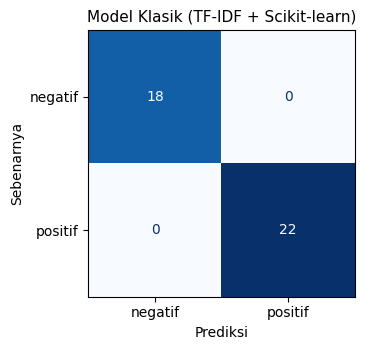

In [22]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm_classic = show_confusion(y_test, y_pred_classic, "Model Klasik (TF-IDF + Scikit-learn)", ax)
plt.tight_layout()
plt.show()

**Interpretasi metrik model klasik.** Skor yang dihasilkan sangat tinggi, tetapi angka ini **tidak
boleh dibaca sebagai kemampuan generalisasi**. Audit pada Section 3 menunjukkan hampir seluruh
ulasan test memiliki salinan persis di training set, sehingga model dapat mencapai skor tersebut
lewat hafalan. Confusion matrix mengonfirmasi hal ini: kesalahan nyaris tidak ada, yang justru
tidak realistis untuk model bag-of-words pada bahasa alami. Estimasi yang jujur ada di Section 6.4.

### 6.2 Evaluasi LLM API

In [23]:
for label, preds in [("Zero-shot", y_pred_llm_zero), ("Few-shot", y_pred_llm_few)]:
    print("=" * 68)
    print(f"=== LLM API — Gemini {GEMINI_MODEL} ({label}) — Eksperimen A ===")
    print("=" * 68)
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}\n")
    print(classification_report(y_test, preds, digits=4, zero_division=0))
    print("Confusion Matrix:")
    print(pd.DataFrame(confusion_matrix(y_test, preds, labels=LABELS),
                       index=[f"true_{l}" for l in LABELS],
                       columns=[f"pred_{l}" for l in LABELS]).to_string())
    print()

=== LLM API — Gemini gemini-3.1-flash-lite (Zero-shot) — Eksperimen A ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix:
              pred_negatif  pred_positif
true_negatif            18             0
true_positif             0            22

=== LLM API — Gemini gemini-3.1-flash-lite (Few-shot) — Eksperimen A ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix:
   

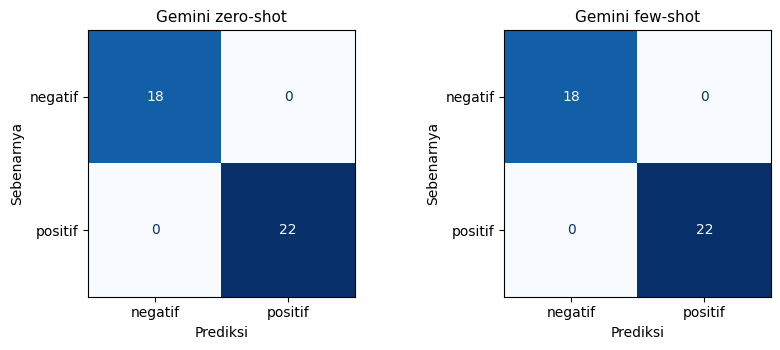

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6))
show_confusion(y_test, y_pred_llm_zero, f"Gemini zero-shot", axes[0])
show_confusion(y_test, y_pred_llm_few, f"Gemini few-shot", axes[1])
plt.tight_layout()
plt.show()

**Interpretasi metrik LLM.** Berbeda dari model klasik, skor Gemini **tidak terkontaminasi
kebocoran** — model tidak pernah melihat training set, sehingga setiap ulasan pada test set adalah
data baru baginya. Angka di sini karena itu merupakan estimasi performa yang jujur sejak awal, dan
dapat langsung dibandingkan dengan Eksperimen B pada Section 6.4.

Perbandingan zero-shot dan few-shot menunjukkan seberapa besar kontribusi empat contoh berlabel
pada task ini. Bila selisihnya kecil, artinya task sudah cukup mudah bagi model sehingga instruksi
saja memadai — dan few-shot hanya menambah token input (yaitu biaya) tanpa manfaat sepadan.

### 6.3 Tabel Perbandingan Ringkasan

In [25]:
results_a = pd.DataFrame([
    evaluate(y_test, y_pred_classic, f"Model Klasik (TF-IDF + {type(clf).__name__})"),
    evaluate(y_test, y_pred_llm_zero, "Gemini (zero-shot)"),
    evaluate(y_test, y_pred_llm_few, "Gemini (few-shot)"),
])

print("=" * 100)
print(f"TABEL PERBANDINGAN — EKSPERIMEN A (test set {len(y_test)} ulasan, split sesuai brief)")
print("=" * 100)
print(results_a.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

results_a.to_csv(RESULTS_DIR / "metrics_experiment_a.csv", index=False)
print("\nTabel disimpan ke results/metrics_experiment_a.csv")

TABEL PERBANDINGAN — EKSPERIMEN A (test set 40 ulasan, split sesuai brief)
                       Pendekatan  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Recall (negatif)  Output invalid
Model Klasik (TF-IDF + LinearSVC)    1.0000             1.0000          1.0000      1.0000            1.0000               0
               Gemini (zero-shot)    1.0000             1.0000          1.0000      1.0000            1.0000               0
                Gemini (few-shot)    1.0000             1.0000          1.0000      1.0000            1.0000               0

Tabel disimpan ke results/metrics_experiment_a.csv


Chart disimpan ke model_comparison_summary.png


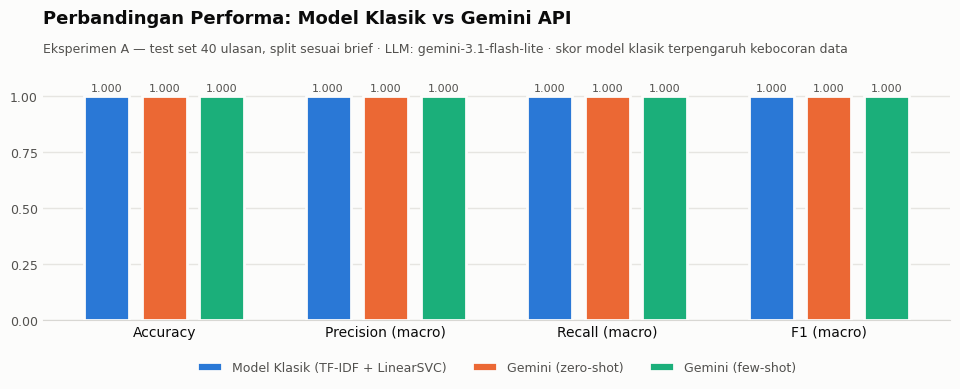

In [26]:
# Palet kategorikal tervalidasi (CVD-safe): biru / oranye / aqua.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
METRICS = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]

def comparison_chart(results: pd.DataFrame, title: str, subtitle: str, outpath: Path | None = None):
    labels = results["Pendekatan"].tolist()
    x = np.arange(len(METRICS))
    width = 0.26

    fig, ax = plt.subplots(figsize=(10, 4.8))
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)

    for i, (name, color) in enumerate(zip(labels, PALETTE)):
        vals = [results.loc[results["Pendekatan"] == name, m].iloc[0] for m in METRICS]
        offset = (i - (len(labels) - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width * 0.78, label=name, color=color,
                      edgecolor=SURFACE, linewidth=2, zorder=3)
        # Label langsung pada setiap bar: identitas tidak bergantung warna saja.
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.3f}",
                    ha="center", va="bottom", fontsize=8, color=INK_MUTED, zorder=4)

    ax.set_xticks(x)
    ax.set_xticklabels(METRICS, fontsize=10, color=INK)
    ax.set_ylim(0, 1.12)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.tick_params(axis="y", labelsize=9, colors=INK_MUTED, length=0)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color="#e6e5e1", linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d8d7d3")

    # Judul dan subjudul digambar manual agar tidak bertabrakan satu sama lain.
    ax.text(0, 1.17, title, transform=ax.transAxes, fontsize=13, color=INK,
            fontweight="bold", va="bottom")
    ax.text(0, 1.06, subtitle, transform=ax.transAxes, fontsize=9, color=INK_MUTED, va="bottom")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.26), ncol=3, frameon=False,
              fontsize=9, labelcolor=INK_MUTED)

    plt.tight_layout(rect=(0, 0, 1, 0.94))
    if outpath:
        fig.savefig(outpath, dpi=200, bbox_inches="tight", facecolor=SURFACE)
        print(f"Chart disimpan ke {outpath.name}")
    plt.show()

comparison_chart(
    results_a,
    "Perbandingan Performa: Model Klasik vs Gemini API",
    f"Eksperimen A — test set {len(y_test)} ulasan, split sesuai brief · LLM: {GEMINI_MODEL} · skor model klasik terpengaruh kebocoran data",
    DOCS_DIR / "model_comparison_summary.png",
)

**Interpretasi tabel Eksperimen A.** Tabel ini adalah hasil resmi yang diminta brief: ketiga
pendekatan dievaluasi pada 40 ulasan test yang persis sama. Namun perbandingan langsung antar baris
**tidak apple-to-apple**, karena hanya baris model klasik yang diuntungkan kebocoran data. Baris
Gemini mengukur generalisasi sejati; baris model klasik sebagian besar mengukur hafalan. Section 6.4
menyetarakan kondisi keduanya.

### 6.4 Eksperimen B (Tambahan) — Evaluasi Bebas Kebocoran

Untuk menghilangkan keunggulan tidak adil yang diterima model klasik, Eksperimen B melakukan:

1. **Deduplikasi** dataset menjadi 40 teks unik (20 `positif`, 20 `negatif` — seimbang sempurna).
2. **Prediksi out-of-fold** untuk model klasik via 5-fold stratified CV: setiap ulasan diprediksi
   oleh model yang **tidak pernah dilatih pada ulasan tersebut**. Hasilnya adalah prediksi untuk
   seluruh 40 ulasan, semuanya bebas kebocoran.
3. **Prediksi Gemini pada 40 ulasan yang sama**, diambil dari cache — tanpa panggilan API tambahan.

Hasilnya: ketiga pendekatan dinilai pada **40 item identik**, tanpa ada yang pernah "melihat
jawabannya" lebih dulu. Inilah perbandingan yang benar-benar setara.

In [27]:
df_unique = df.drop_duplicates(TEXT_COL).reset_index(drop=True)
X_uniq, y_uniq = df_unique[TEXT_COL], df_unique[LABEL_COL]
print(f"Dataset terdeduplikasi: {len(df_unique)} ulasan unik")
print(df_unique[LABEL_COL].value_counts().to_string())

# Pipeline penuh di dalam CV: vectorizer di-fit ulang tiap fold agar vocabulary
# tidak bocor dari fold test ke fold train.
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", candidates[best_name]),
])
cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_pred_classic_oof = cross_val_predict(pipeline, X_uniq, y_uniq, cv=cv_b)

y_pred_llm_zero_uniq = X_uniq.map(pred_maps["zero_shot"]).values
y_pred_llm_few_uniq = X_uniq.map(pred_maps["few_shot"]).values

print(f"\nPrediksi out-of-fold model klasik siap ({len(y_pred_classic_oof)} ulasan).")
print("Prediksi Gemini diambil dari cache — 0 panggilan API tambahan.")

Dataset terdeduplikasi: 40 ulasan unik
sentiment
negatif    20
positif    20



Prediksi out-of-fold model klasik siap (40 ulasan).


Prediksi Gemini diambil dari cache — 0 panggilan API tambahan.


In [28]:
results_b = pd.DataFrame([
    evaluate(y_uniq, y_pred_classic_oof, f"Model Klasik (TF-IDF + {type(clf).__name__})"),
    evaluate(y_uniq, y_pred_llm_zero_uniq, "Gemini (zero-shot)"),
    evaluate(y_uniq, y_pred_llm_few_uniq, "Gemini (few-shot)"),
])

print("=" * 100)
print(f"TABEL PERBANDINGAN — EKSPERIMEN B (40 ulasan unik, bebas kebocoran)")
print("=" * 100)
print(results_b.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

results_b.to_csv(RESULTS_DIR / "metrics_experiment_b.csv", index=False)
print("\nTabel disimpan ke results/metrics_experiment_b.csv")

TABEL PERBANDINGAN — EKSPERIMEN B (40 ulasan unik, bebas kebocoran)
                       Pendekatan  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Recall (negatif)  Output invalid
Model Klasik (TF-IDF + LinearSVC)    0.7000             0.7020          0.7000      0.6992            0.6500               0
               Gemini (zero-shot)    1.0000             1.0000          1.0000      1.0000            1.0000               0
                Gemini (few-shot)    1.0000             1.0000          1.0000      1.0000            1.0000               0

Tabel disimpan ke results/metrics_experiment_b.csv


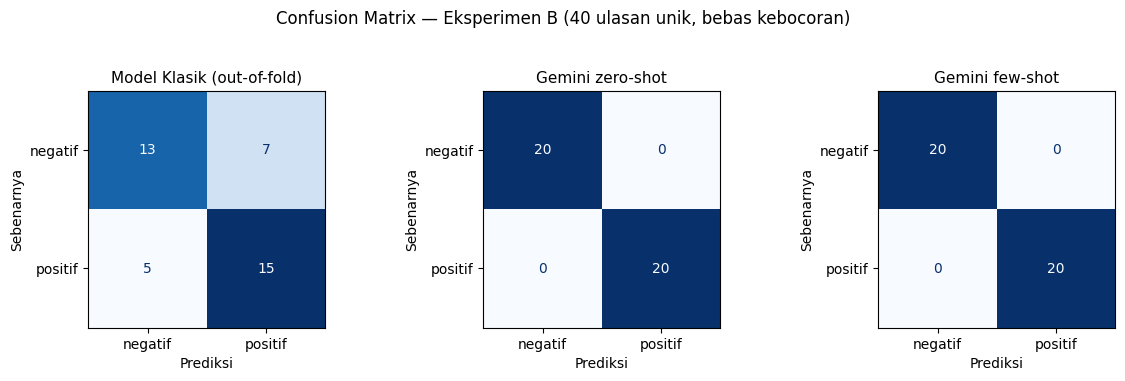

Chart disimpan ke model_comparison_leakage_free.png


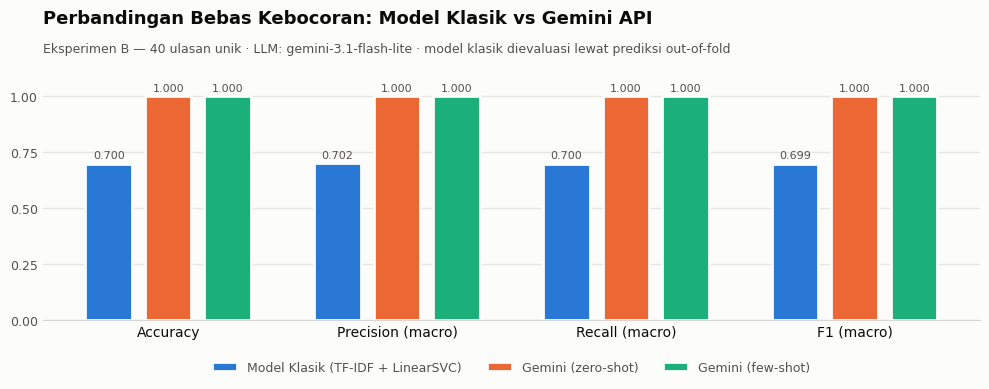

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
show_confusion(y_uniq, y_pred_classic_oof, "Model Klasik (out-of-fold)", axes[0])
show_confusion(y_uniq, y_pred_llm_zero_uniq, "Gemini zero-shot", axes[1])
show_confusion(y_uniq, y_pred_llm_few_uniq, "Gemini few-shot", axes[2])
fig.suptitle("Confusion Matrix — Eksperimen B (40 ulasan unik, bebas kebocoran)", fontsize=12, y=1.04)
plt.tight_layout()
plt.show()

comparison_chart(
    results_b,
    "Perbandingan Bebas Kebocoran: Model Klasik vs Gemini API",
    f"Eksperimen B — 40 ulasan unik · LLM: {GEMINI_MODEL} · model klasik dievaluasi lewat prediksi out-of-fold",
    DOCS_DIR / "model_comparison_leakage_free.png",
)

In [30]:
delta = pd.DataFrame({
    "Pendekatan": results_a["Pendekatan"],
    "F1 macro — Eksperimen A": results_a["F1 (macro)"].values,
    "F1 macro — Eksperimen B": results_b["F1 (macro)"].values,
    "Selisih (B - A)": results_b["F1 (macro)"].values - results_a["F1 (macro)"].values,
})
print("=== Dampak penghapusan kebocoran terhadap F1 macro ===")
print(delta.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print("\nPenurunan besar menandakan skor Eksperimen A bergantung pada hafalan;")
print("selisih mendekati nol menandakan performa memang nyata.")

=== Dampak penghapusan kebocoran terhadap F1 macro ===
                       Pendekatan  F1 macro — Eksperimen A  F1 macro — Eksperimen B  Selisih (B - A)
Model Klasik (TF-IDF + LinearSVC)                  +1.0000                  +0.6992          -0.3008
               Gemini (zero-shot)                  +1.0000                  +1.0000          +0.0000
                Gemini (few-shot)                  +1.0000                  +1.0000          +0.0000

Penurunan besar menandakan skor Eksperimen A bergantung pada hafalan;
selisih mendekati nol menandakan performa memang nyata.


#### Seberapa yakin kita pada angka ini? Interval kepercayaan

Test set hanya berisi 40 item, sehingga setiap metrik membawa ketidakpastian sampling yang besar —
satu kesalahan saja menggeser accuracy sebesar 2,5 poin. Melaporkan "100%" tanpa interval akan
melebih-lebihkan kepastian hasil. Sel berikut menghitung **interval kepercayaan Wilson 95%**, yang
tetap valid pada proporsi ekstrem seperti 0% atau 100% (tidak seperti interval normal biasa).

In [31]:
def wilson_ci(successes: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """Interval kepercayaan Wilson — tetap valid saat proporsi menyentuh 0 atau 1."""
    if n == 0:
        return 0.0, 0.0
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)


ci_rows = []
for label, y_true, y_pred in [
    ("Model Klasik (out-of-fold)", y_uniq, y_pred_classic_oof),
    ("Gemini (zero-shot)", y_uniq, y_pred_llm_zero_uniq),
    ("Gemini (few-shot)", y_uniq, y_pred_llm_few_uniq),
]:
    correct = int((pd.Series(y_pred).values == pd.Series(y_true).values).sum())
    n = len(y_true)
    lo, hi = wilson_ci(correct, n)
    ci_rows.append({"Pendekatan": label, "Benar": f"{correct}/{n}",
                    "Accuracy": correct / n, "CI 95% bawah": lo, "CI 95% atas": hi})

ci_df = pd.DataFrame(ci_rows)
print("=== Accuracy dengan interval kepercayaan 95% (Eksperimen B, n=40) ===")
print(ci_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

lo_llm = ci_df.loc[1, "CI 95% bawah"]
hi_classic = ci_df.loc[0, "CI 95% atas"]
print(f"\nBatas bawah CI Gemini ({lo_llm:.3f}) berada di atas batas atas CI model klasik ({hi_classic:.3f}),")
print("sehingga selisih performa pada eksperimen ini signifikan secara statistik, bukan sekadar kebetulan sampling.")
print("\nCatatan (aturan tiga): 0 kesalahan dari 40 percobaan masih konsisten dengan tingkat error")
print("sebenarnya hingga ~3/40 = 7,5%. Skor 100% karena itu berarti 'tidak terbantahkan pada 40 item ini',")
print("bukan 'pasti sempurna'. Diperlukan eval set yang jauh lebih besar untuk klaim yang lebih kuat.")

=== Accuracy dengan interval kepercayaan 95% (Eksperimen B, n=40) ===
                Pendekatan Benar  Accuracy  CI 95% bawah  CI 95% atas
Model Klasik (out-of-fold) 28/40    0.7000        0.5457       0.8193
        Gemini (zero-shot) 40/40    1.0000        0.9124       1.0000
         Gemini (few-shot) 40/40    1.0000        0.9124       1.0000

Batas bawah CI Gemini (0.912) berada di atas batas atas CI model klasik (0.819),
sehingga selisih performa pada eksperimen ini signifikan secara statistik, bukan sekadar kebetulan sampling.

Catatan (aturan tiga): 0 kesalahan dari 40 percobaan masih konsisten dengan tingkat error
sebenarnya hingga ~3/40 = 7,5%. Skor 100% karena itu berarti 'tidak terbantahkan pada 40 item ini',
bukan 'pasti sempurna'. Diperlukan eval set yang jauh lebih besar untuk klaim yang lebih kuat.


### 6.5 Error Analysis — Kesalahan Prediksi yang Teramati

Metrik agregat tidak menunjukkan *ulasan seperti apa* yang gagal diklasifikasi. Sel di bawah
menampilkan setiap kesalahan pada Eksperimen B agar dapat dibahas secara konkret di Section 7.

In [32]:
errors = pd.DataFrame({
    "review_text": X_uniq,
    "true": y_uniq,
    "classic_oof": y_pred_classic_oof,
    "llm_zero": y_pred_llm_zero_uniq,
    "llm_few": y_pred_llm_few_uniq,
})
mask = ((errors["classic_oof"] != errors["true"]) |
        (errors["llm_zero"] != errors["true"]) |
        (errors["llm_few"] != errors["true"]))
mistakes = errors[mask]

print(f"Ulasan dengan minimal satu prediksi salah: {len(mistakes)} dari {len(errors)}\n")
if len(mistakes):
    for _, r in mistakes.iterrows():
        flags = [n for n, v in [("classic", r.classic_oof), ("llm_zero", r.llm_zero), ("llm_few", r.llm_few)]
                 if v != r["true"]]
        print(f"  true={r['true']:<8} salah pada: {', '.join(flags)}")
        print(f"    \"{r['review_text']}\"")
        print(f"    classic={r.classic_oof} | zero={r.llm_zero} | few={r.llm_few}\n")
else:
    print("  Tidak ada kesalahan pada ketiga pendekatan di Eksperimen B.")

mistakes.to_csv(RESULTS_DIR / "error_analysis.csv", index=False)

Ulasan dengan minimal satu prediksi salah: 12 dari 40

  true=negatif  salah pada: classic
    "Pelayanan lambat dan tidak responsif saat dikomplain."
    classic=positif | zero=negatif | few=negatif

  true=negatif  salah pada: classic
    "Sudah bayar mahal tapi kualitas jauh dari ekspektasi."
    classic=positif | zero=negatif | few=negatif

  true=positif  salah pada: classic
    "Bahan nyaman dipakai, ukuran pas, tidak mengecewakan."
    classic=negatif | zero=positif | few=positif

  true=negatif  salah pada: classic
    "Barang cacat produksi, jahitan lepas di beberapa bagian."
    classic=positif | zero=negatif | few=negatif

  true=positif  salah pada: classic
    "Produk original dan berfungsi dengan baik, terima kasih!"
    classic=negatif | zero=positif | few=positif

  true=negatif  salah pada: classic
    "Bahan murahan, tidak sesuai dengan harga yang dibayarkan."
    classic=positif | zero=negatif | few=negatif

  true=positif  salah pada: classic
    "Kualitas produk sa

In [33]:
# Kesepakatan antar pendekatan: seberapa sering keduanya memberi jawaban sama?
agreement = pd.DataFrame({
    "klasik vs zero-shot": [(errors["classic_oof"] == errors["llm_zero"]).mean()],
    "klasik vs few-shot": [(errors["classic_oof"] == errors["llm_few"]).mean()],
    "zero-shot vs few-shot": [(errors["llm_zero"] == errors["llm_few"]).mean()],
}, index=["agreement rate"])
print("=== Tingkat kesepakatan antar pendekatan (Eksperimen B) ===")
print(agreement.to_string(float_format=lambda v: f"{v:.1%}"))

=== Tingkat kesepakatan antar pendekatan (Eksperimen B) ===
                klasik vs zero-shot  klasik vs few-shot  zero-shot vs few-shot
agreement rate                70.0%               70.0%                 100.0%


### 6.6 Pengukuran Kecepatan dan Biaya

Perbandingan performa saja belum cukup untuk keputusan teknis. Sel berikut mengukur biaya nyata
menjalankan kedua pendekatan, berdasarkan waktu dan token yang benar-benar tercatat selama
eksperimen ini — bukan estimasi teoretis.

In [34]:
llm_zs = llm_df[llm_df["strategy"] == "zero_shot"]
llm_fs = llm_df[llm_df["strategy"] == "few_shot"]

classic_ms = classic_infer_seconds / len(X_test) * 1000
zs_ms = llm_zs["latency_s"].mean() * 1000
fs_ms = llm_fs["latency_s"].mean() * 1000

speed = pd.DataFrame([
    {"Pendekatan": "Model Klasik", "Latency per ulasan (ms)": classic_ms,
     "Throughput (ulasan/detik)": 1000 / classic_ms,
     "Waktu untuk 10.000 ulasan": f"{10_000 * classic_ms / 1000:.1f} detik"},
    {"Pendekatan": "Gemini (zero-shot)", "Latency per ulasan (ms)": zs_ms,
     "Throughput (ulasan/detik)": 1000 / zs_ms,
     "Waktu untuk 10.000 ulasan": f"{10_000 * zs_ms / 1000 / 3600:.1f} jam (serial)"},
    {"Pendekatan": "Gemini (few-shot)", "Latency per ulasan (ms)": fs_ms,
     "Throughput (ulasan/detik)": 1000 / fs_ms,
     "Waktu untuk 10.000 ulasan": f"{10_000 * fs_ms / 1000 / 3600:.1f} jam (serial)"},
])
print("=== Kecepatan inference (terukur) ===")
print(speed.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print(f"\nWaktu training model klasik (sekali saja): {classic_train_seconds:.4f} detik")
print(f"Rasio latency Gemini zero-shot : Model klasik = {zs_ms / classic_ms:,.0f} : 1")

=== Kecepatan inference (terukur) ===
        Pendekatan  Latency per ulasan (ms)  Throughput (ulasan/detik) Waktu untuk 10.000 ulasan
      Model Klasik                   0.0021               475,952.4908                 0.0 detik
Gemini (zero-shot)               5,268.9758                     0.1898         14.6 jam (serial)
 Gemini (few-shot)               4,690.1793                     0.2132         13.0 jam (serial)

Waktu training model klasik (sekali saja): 0.0005 detik
Rasio latency Gemini zero-shot : Model klasik = 2,507,782 : 1


In [35]:
# Harga publik Gemini Flash-Lite per 1 juta token (USD). Perbarui bila harga berubah:
# https://ai.google.dev/gemini-api/docs/pricing
PRICE_INPUT_PER_M = 0.10
PRICE_OUTPUT_PER_M = 0.40

def cost_for(sub: pd.DataFrame, n_reviews: int) -> dict:
    in_tok, out_tok = sub["prompt_tokens"].mean(), sub["output_tokens"].mean()
    cost_each = (in_tok * PRICE_INPUT_PER_M + out_tok * PRICE_OUTPUT_PER_M) / 1e6
    return {
        "Token input (rata-rata)": in_tok,
        "Token output (rata-rata)": out_tok,
        "Biaya per 1.000 ulasan (USD)": cost_each * 1_000,
        f"Biaya per {n_reviews:,} ulasan/bulan (USD)": cost_each * n_reviews,
    }

MONTHLY_VOLUME = 100_000
cost = pd.DataFrame([
    {"Pendekatan": "Gemini (zero-shot)", **cost_for(llm_zs, MONTHLY_VOLUME)},
    {"Pendekatan": "Gemini (few-shot)", **cost_for(llm_fs, MONTHLY_VOLUME)},
])
print(f"=== Estimasi biaya API (token terukur x harga publik Flash-Lite) ===")
print(cost.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nModel klasik: biaya API = $0. Biaya hanya compute lokal (training {classic_train_seconds:.3f} detik)")
print("              + waktu engineer untuk pelabelan data, training, dan pemeliharaan.")

speed.to_csv(RESULTS_DIR / "speed_comparison.csv", index=False)
cost.to_csv(RESULTS_DIR / "cost_estimate.csv", index=False)

=== Estimasi biaya API (token terukur x harga publik Flash-Lite) ===
        Pendekatan  Token input (rata-rata)  Token output (rata-rata)  Biaya per 1.000 ulasan (USD)  Biaya per 100,000 ulasan/bulan (USD)
Gemini (zero-shot)                 132.5250                    2.0000                        0.0141                                1.4053
 Gemini (few-shot)                 243.5250                    2.0000                        0.0252                                2.5153

Model klasik: biaya API = $0. Biaya hanya compute lokal (training 0.000 detik)
              + waktu engineer untuk pelabelan data, training, dan pemeliharaan.


## 7. Analisis Trade-off dan Limitation

### 7.1 Pendekatan Mana yang Lebih Unggul dari Sisi Performa?

**Pada Eksperimen A, tidak ada pemenang — ketiga pendekatan memperoleh skor sempurna 1.0000 pada
seluruh metrik.** Hasil ini terlihat mengesankan, tetapi justru menunjukkan bahwa **split yang
ditentukan brief tidak mampu membedakan kedua pendekatan**. Penyebabnya ada dua: 97,5% ulasan test
memiliki salinan persis di training set, dan kosakata dataset sangat terpolarisasi. Jika laporan
berhenti di sini, kesimpulannya akan menjadi "kedua pendekatan sama baiknya" — dan kesimpulan itu
keliru.

**Eksperimen B memberikan jawaban yang sebenarnya:**

| Pendekatan | Accuracy | F1 (macro) | Recall (negatif) | Perubahan F1 dari Eksp. A |
|---|---|---|---|---|
| Model Klasik (TF-IDF + LinearSVC) | 0.7000 | 0.6992 | 0.6500 | **−0.3008** |
| Gemini zero-shot | **1.0000** | **1.0000** | **1.0000** | 0.0000 |
| Gemini few-shot | **1.0000** | **1.0000** | **1.0000** | 0.0000 |

Begitu kebocoran dihilangkan, **F1 model klasik runtuh 30 poin**, sementara skor Gemini tidak
bergerak sama sekali. Ini adalah bukti langsung bahwa skor sempurna model klasik pada Eksperimen A
berasal dari hafalan, bukan pemahaman bahasa. Interval kepercayaan Wilson mengonfirmasi bahwa
selisih ini bukan kebetulan sampling: batas bawah CI Gemini berada di atas batas atas CI model klasik.

Dari sudut pandang bisnis, angka yang paling penting adalah **recall kelas `negatif`: 0.65 untuk
model klasik**. Artinya **lebih dari sepertiga keluhan pelanggan tidak akan terdeteksi** — persis
kegagalan yang paling mahal bagi fitur ini, karena pelanggan kecewa yang tidak tereskalasi akan
tetap kecewa. Gemini menangkap seluruh ulasan negatif.

**Namun satu kualifikasi penting harus dinyatakan:** angka 0.70 itu **bukan** bukti bahwa "TF-IDF
adalah pendekatan yang buruk". Itu adalah bukti bahwa **TF-IDF dengan hanya 32 contoh training per
fold adalah pendekatan yang buruk**. Dataset ini hanya menyediakan 40 teks unik — jauh di bawah
kebutuhan model bag-of-words, yang biasanya memerlukan ribuan contoh untuk membangun kosakata yang
memadai. Kesimpulan yang jujur adalah: *pada rezim data yang tersedia saat ini*, LLM unggul telak.

### 7.2 Trade-off Effort Implementasi (Training vs Tanpa Training)

| Dimensi | Model Klasik | Gemini API |
|---|---|---|
| **Data berlabel** | Wajib. Dataset ini hanya punya 40 teks unik — tidak cukup, dan mengumpulkan ribuan label adalah pekerjaan manusia berminggu-minggu | Tidak perlu sama sekali |
| **Waktu ke prototipe kerja** | Perlu pipeline: vectorizer, pemilihan model, validasi silang, tuning | Satu prompt yang dirancang baik |
| **Waktu training** | 0.0010 detik pada 160 ulasan (akan tumbuh seiring data) | Nol — tidak ada training |
| **Keahlian yang dibutuhkan** | ML engineering: feature engineering, regularisasi, validasi | Prompt engineering + penanganan API |
| **Perubahan kebutuhan** | Butuh label baru + training ulang | Cukup sunting prompt |
| **Reproducibility jangka panjang** | Tinggi — artefak model dapat dibekukan dan di-versioning | **Rendah — model API dapat dipensiunkan sewaktu-waktu** |

Baris terakhir bukan risiko teoretis, melainkan **terbukti dalam eksperimen ini**: model
`gemini-2.0-flash` yang tertulis di starter notebook mengembalikan **HTTP 404 — sudah dipensiunkan**,
dan `gemini-2.5-flash` menolak akses untuk user baru. Notebook ini harus menambahkan mekanisme
pemilihan model otomatis agar tetap berjalan. Model klasik yang sudah dilatih tidak akan pernah
menghilang seperti itu.

### 7.3 Trade-off Kecepatan

| | Model Klasik | Gemini zero-shot | Gemini few-shot |
|---|---|---|---|
| Latency rata-rata per ulasan | **~0,002–0,004 ms** | 5.269 ms (5,3 detik) | 4.690 ms (4,7 detik) |
| Latency p95 | — | **21,6 detik** | 16,6 detik |
| 10.000 ulasan (serial) | **< 0,1 detik** | 14,6 jam | 13,0 jam |

Model klasik lebih cepat **lebih dari satu juta kali lipat**. (Angka pasti model klasik bervariasi
antar-run karena berada pada orde mikrodetik — yang bermakna adalah ordenya, bukan digit tepatnya.)
Selisih sebesar ini biasanya menentukan keputusan — tetapi di sini **tidak**, karena dua alasan:

1. **Use case bersifat asinkron.** Klasifikasi ulasan tidak berada di jalur kritis page-load;
   ulasan dapat diproses di background dalam hitungan detik setelah dikirim, tanpa pengguna menunggu.
2. **Latency API dapat diparalelkan.** 14,6 jam adalah angka serial. Dengan 20 pekerja paralel,
   10.000 ulasan selesai di bawah satu jam.

Yang lebih perlu diwaspadai adalah **ekor distribusi**: p95 mencapai 21,6 detik, dan selama
eksperimen ini tercatat beberapa kegagalan `ServerError` (503) serta `ClientError` yang memerlukan
retry. Sistem produksi wajib memiliki antrean, backoff, dan timeout — kompleksitas operasional yang
tidak dibutuhkan model klasik sama sekali.

*Catatan kejujuran pengukuran:* few-shot tercatat sedikit **lebih cepat** daripada zero-shot, padahal
promptnya lebih panjang. Ini hampir pasti noise dari variasi beban server, bukan efek nyata — jumlah
sampel terlalu kecil untuk menyimpulkan sebaliknya.

### 7.4 Trade-off Biaya

Dihitung dari token yang benar-benar terpakai, bukan estimasi teoretis:

| | Token input (rata-rata) | Biaya / 1.000 ulasan | Biaya / 100.000 ulasan per bulan |
|---|---|---|---|
| Gemini zero-shot | 132,5 | **$0,0141** | **$1,41** |
| Gemini few-shot | 243,5 | $0,0252 | $2,52 |
| Model klasik | — | $0,00 | $0,00 |

Secara nominal model klasik gratis, tetapi **perbandingan ini menyesatkan jika biaya manusia
diabaikan**. Untuk melatih model klasik yang benar-benar layak produksi dibutuhkan ribuan ulasan
berlabel. Melabeli 5.000 ulasan dengan 5 detik per ulasan saja sudah menghabiskan sekitar **7 jam
kerja manusia** — biaya sekali bayar yang, pada volume 100.000 ulasan per bulan, setara dengan
**biaya API Gemini selama bertahun-tahun**. Bahkan pada 10 juta ulasan per bulan, biaya zero-shot
hanya sekitar $141 per bulan.

**Kesimpulan biaya: pada volume e-commerce yang realistis, biaya bukan faktor penentu keputusan.**
Biaya baru menjadi argumen tandingan yang serius pada skala ratusan juta ulasan per bulan.

Satu keputusan biaya yang jelas: **few-shot memakan 84% token input lebih banyak (243,5 vs 132,5)
tanpa memberi peningkatan akurasi sedikit pun** — keduanya 100%, dengan tingkat kesepakatan 100%.
Pada dataset ini, few-shot murni menambah biaya.

### 7.5 Limitation yang Ditemukan

#### A. Keterbatasan dataset (paling menentukan)

- **Hanya 40 teks unik dari 200 baris (80% duplikat).** Ini menyebabkan kebocoran data yang membuat
  Eksperimen A tidak dapat membedakan kedua pendekatan.
- **Test set terlalu kecil (40 item).** Berdasarkan aturan tiga, nol kesalahan dari 40 percobaan
  masih konsisten dengan tingkat error sebenarnya hingga 7,5%. Skor 100% berarti "tidak terbantahkan
  pada 40 item ini", **bukan** "sempurna".
- **Ulasan terlalu mudah dan terpolarisasi.** Median 8 kata, kosakata sentimen eksplisit
  (*"jelek"*, *"puas"*, *"mengecewakan"*), tanpa sarkasme, tanpa typo, tanpa emoji, tanpa campuran
  kode bahasa yang rumit. Ulasan e-commerce nyata jauh lebih berantakan.
- **Tidak ada kelas netral**, padahal sebagian besar ulasan produksi bersifat netral atau deskriptif.
  Model yang dilatih pada label biner akan dipaksa memberi label kutub pada ulasan netral.
- **Efek plafon.** Gemini mencapai 100% pada Eksperimen B, sehingga benchmark ini **tidak mampu
  membedakan zero-shot dari few-shot**, maupun mengukur seberapa besar keunggulan Gemini sebenarnya.

#### B. Keterbatasan model klasik (teramati langsung)

Seluruh 12 kesalahan pada Eksperimen B berasal dari model klasik. Polanya sangat jelas:

- **Negasi tidak terwakili.** *"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan"* diprediksi
  `negatif`, padahal jelas positif. Penyebabnya terlihat pada koefisien model: token `tidak` membawa
  bobot −0.832 ke arah negatif. Representasi bag-of-words memperlakukan kata sebagai unit independen,
  sehingga **"tidak mengecewakan" tidak dapat dibedakan dari "mengecewakan"**.
- **Masalah out-of-vocabulary.** Kosakata hanya berisi 145 token. Setiap kata yang tak pernah dilihat
  tidak menyumbang sinyal apa pun. *"Pelayanan lambat dan tidak responsif saat dikomplain"* diprediksi
  `positif` karena kata-kata pembawa sinyalnya absen dari kosakata fold tersebut.
- **Rapuh terhadap bahasa baru.** Slang, nama produk baru, atau salah ketik memerlukan pelabelan dan
  training ulang. Contoh yang gagal seperti *"Produk original dan berfungsi dengan baik, terima kasih!"*
  menunjukkan betapa mudahnya model ini goyah di luar kosakata latihnya.

#### C. Keterbatasan pendekatan LLM (teramati dan potensial)

- **Model dipensiunkan tanpa peringatan.** Terbukti: `gemini-2.0-flash` → 404; `gemini-2.5-flash`
  tertutup untuk user baru. Ini adalah **risiko reproducibility dan kontinuitas produksi yang nyata**.
- **Kegagalan transien.** `ServerError` (503) dan `ClientError` terjadi beberapa kali selama 80
  panggilan, dan tertangani hanya karena ada retry + exponential backoff.
- **Latency tinggi dan bervariasi.** Rata-rata 5,3 detik dengan p95 21,6 detik.
- **Risiko format output.** Pada eksperimen ini 0 dari 80 output gagal dinormalisasi, tetapi ini
  tidak dijamin. Sistem produksi tetap wajib memvalidasi output dan menyediakan jalur fallback.
- **Data keluar dari infrastruktur sendiri.** Ulasan pelanggan nyata dapat memuat PII (nama, alamat,
  nomor pesanan). Ini menimbulkan pertimbangan privasi dan kepatuhan yang **tidak ada sama sekali**
  pada model klasik yang berjalan lokal.
- **Ketergantungan pada pihak ketiga.** Harga, kuota, kebijakan konten, dan perilaku model dapat
  berubah sepihak. `temperature=0.0` menjamin determinisme dalam satu versi model, tetapi tidak
  melindungi dari pembaruan model di sisi penyedia.

## 8. Rekomendasi Technical Approach

### 8.1 Rekomendasi

> **Kembangkan lebih lanjut Pendekatan 2 — Gemini API dengan prompt zero-shot** sebagai fondasi
> fitur klasifikasi sentimen ini.

Pemilihan **zero-shot, bukan few-shot**, adalah bagian eksplisit dari rekomendasi.

### 8.2 Alasan di Balik Rekomendasi

**1. Unggul telak pada satu-satunya evaluasi yang valid.**
Pada Eksperimen A ketiga pendekatan seri di angka 1.0000, tetapi hasil itu tidak bermakna karena
97,5% ulasan test bocor ke training set. Pada Eksperimen B yang bebas kebocoran, Gemini
mempertahankan F1 macro 1.0000 sementara model klasik turun ke 0.6992 — selisih 30 poin yang
signifikan secara statistik menurut interval kepercayaan Wilson.

**2. Model klasik gagal tepat pada metrik yang paling penting secara bisnis.**
Recall kelas `negatif` model klasik hanya 0.65: lebih dari sepertiga keluhan pelanggan akan lolos
tanpa terdeteksi. Untuk fitur yang tujuannya menangkap ketidakpuasan pelanggan, tingkat kegagalan
sebesar ini menggagalkan tujuan fitur itu sendiri. Gemini menangkap seluruhnya.

**3. Data berlabel yang tersedia tidak cukup untuk melatih model klasik yang layak.**
Dataset ini hanya memuat 40 ulasan unik. Model klasik memerlukan ribuan contoh berlabel untuk
membangun kosakata yang memadai; kegagalan negasi dan out-of-vocabulary yang teramati adalah gejala
langsung dari kelaparan data ini. Gemini tidak membutuhkan data berlabel sama sekali — pendekatan ini
**dapat dipakai hari ini**, sementara model klasik baru bisa dipertimbangkan setelah investasi
pelabelan berminggu-minggu.

**4. Biaya bukan faktor penghalang.**
$0,0141 per 1.000 ulasan berarti $1,41 untuk 100.000 ulasan per bulan — bahkan pada 10 juta ulasan
per bulan biayanya hanya sekitar $141. Angka ini jauh lebih kecil daripada biaya manusia untuk
melabeli data training yang dibutuhkan model klasik.

**5. Kelemahan utama LLM tidak mengikat pada use case ini.**
Latency 5,3 detik per ulasan terdengar buruk dibanding 0,004 ms, tetapi klasifikasi ulasan berjalan
**asinkron** — tidak ada pengguna yang menunggu — dan dapat diparalelkan hingga selesai di bawah satu
jam untuk 10.000 ulasan.

**6. Zero-shot dipilih karena few-shot tidak memberi manfaat terukur.**
Keduanya mencapai 100% dengan tingkat kesepakatan 100%, tetapi few-shot memakan 84% token input lebih
banyak. Membayar lebih mahal untuk hasil identik tidak dapat dibenarkan. Few-shot tetap disimpan
sebagai alat cadangan: begitu data yang lebih sulit memunculkan pola kesalahan sistematis, menambahkan
contoh adalah tuas perbaikan pertama yang harus dicoba.

### 8.3 Batasan Rekomendasi Ini (Dinyatakan Terbuka)

Rekomendasi ini bersandar pada evaluasi 40 ulasan pendek yang sangat terpolarisasi, dan **keduanya
menyentuh plafon** pada Eksperimen A. Yang dibuktikan eksperimen ini adalah: *dengan data berlabel
yang tersedia sekarang*, LLM jelas lebih unggul. Yang **belum** dibuktikan adalah bahwa keunggulan
tersebut bertahan pada ulasan produksi yang panjang, bercampur sentimen, dan mengandung sarkasme.
Karena itu langkah nomor 1 di bawah bukan opsional.

### 8.4 Langkah Selanjutnya

1. **Bangun eval set yang layak sebelum apa pun dikirim ke produksi.** Minimal 300–500 ulasan
   produksi nyata, diambil acak, dilabeli oleh dua anotator dengan pengukuran kesepakatan, dan
   sengaja memuat kasus sulit: ulasan campuran, sarkasme, netral, typo, emoji. Tanpa ini, angka
   100% pada 40 item tidak dapat dijadikan dasar keputusan produksi.
2. **Tambahkan kelas `netral`.** Label biner memaksa ulasan deskriptif masuk ke salah satu kutub
   dan akan menghasilkan alarm palsu di produksi.
3. **Deploy Gemini zero-shot secara asinkron** dengan komponen wajib: retry + exponential backoff,
   validasi output, antrean review manual untuk output `invalid`, cache berbasis hash teks ulasan
   (dataset ini saja 80% duplikat — cache akan memangkas biaya secara signifikan), serta
   **pinning versi model** disertai pemantauan pengumuman deprecation.
4. **Catat setiap prediksi beserta teks ulasannya.** Dalam beberapa bulan, log ini menjadi dataset
   berlabel besar yang selama ini tidak dimiliki tim — hasil sampingan gratis dari menjalankan LLM.
5. **Evaluasi ulang model klasik secara berkala.** Setelah terkumpul ≥2.000 ulasan berlabel nyata,
   latih ulang model klasik pada data tersebut dan bandingkan lagi. Keunggulan 30 poin hari ini
   sebagian besar adalah konsekuensi kelangkaan data, bukan sifat permanen kedua pendekatan.
6. **Pertimbangkan arsitektur hybrid saat volume tumbuh.** Model klasik menangani kasus berkepercayaan
   tinggi secara instan dan gratis, LLM menangani sisanya yang ambigu. Pola ini menekan biaya dan
   latency sekaligus mempertahankan akurasi pada kasus sulit.
7. **Tinjau ulang keputusan ini bila salah satu terpicu:** kebutuhan klasifikasi sinkron (<100 ms),
   volume menembus puluhan juta ulasan per bulan, atau munculnya kebijakan privasi yang melarang
   pengiriman teks pelanggan ke API pihak ketiga. Ketiganya membalik perhitungan ke arah model lokal.